Customer Churn Prediction Using Decision Tree Classification

Internship: Codveda Technologies, Machine Learning

Level: Level 2, Intermediate

Task: Decision Tree Classification

Objective: Build a Decision Tree classification model that predicts customer churn using customer account information, service usage, and customer support data.

Tools: Python, pandas, Matplotlib, and scikit-learn.

Evaluation metrics: Accuracy, confusion matrix, precision, recall, and F1-score.

In [ ]:
import pandas as pd

file_id = "1YF73QNFjNYNnqqN2vHymT3NQG3qwd4RD"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (2666, 20)


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [ ]:
# Create a working copy
df_cleaned = df.drop_duplicates().copy()

# Separate features and target
X = df_cleaned.drop(columns=["Churn"])
y = df_cleaned["Churn"]

print("Dataset shape after removing duplicates:", df_cleaned.shape)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nChurn distribution:")
print(y.value_counts())

Dataset shape after removing duplicates: (2666, 20)
Feature shape: (2666, 19)
Target shape: (2666,)

Churn distribution:
Churn
False    2278
True      388
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# Identify feature types
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Preprocess numeric columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the Decision Tree model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42,
        class_weight="balanced"
    ))
])

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Preprocessing pipeline created successfully!")

Training samples: 2132
Testing samples: 534
Preprocessing pipeline created successfully!


In [ ]:
model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8951

Confusion Matrix:
[[424  32]
 [ 24  54]]

Classification Report:
              precision    recall  f1-score   support

       False       0.95      0.93      0.94       456
        True       0.63      0.69      0.66        78

    accuracy                           0.90       534
   macro avg       0.79      0.81      0.80       534
weighted avg       0.90      0.90      0.90       534



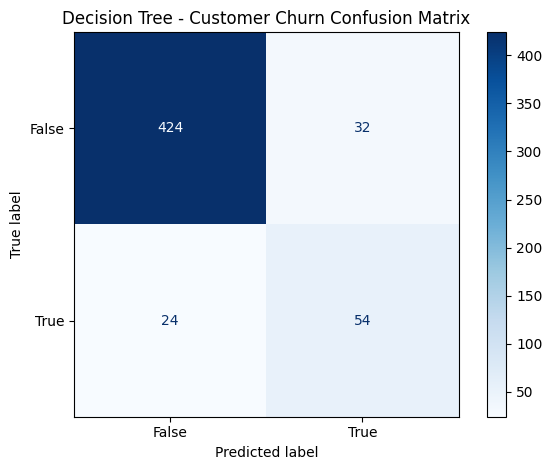

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    values_format="d"
)

plt.title("Decision Tree - Customer Churn Confusion Matrix")
plt.tight_layout()
plt.show()

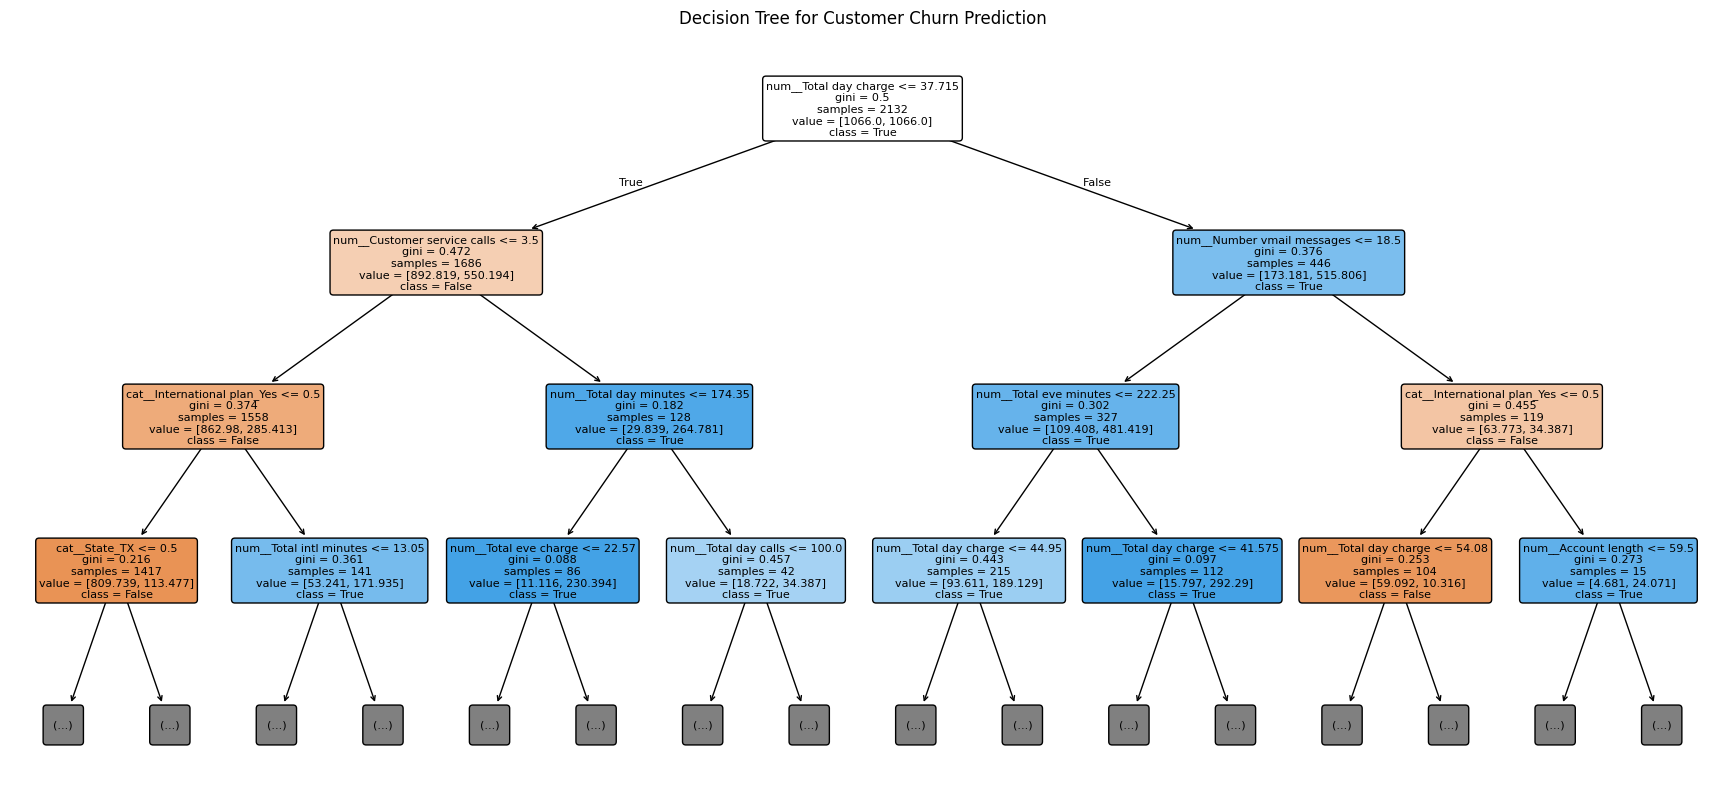

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

preprocessor_fitted = model.named_steps["preprocessor"]
tree_classifier = model.named_steps["classifier"]

feature_names = preprocessor_fitted.get_feature_names_out()

plt.figure(figsize=(22, 10))

plot_tree(
    tree_classifier,
    feature_names=feature_names,
    class_names=[str(c) for c in tree_classifier.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree for Customer Churn Prediction")
plt.show()